# Local Green, Global Red II

This companion has five levels:

1. **Intuition:** see the four Boolean possibilities.
2. **Practice:** move the evaluators and governance checks with widgets.
3. **Proof:** reproduce the finite counterexamples.
4. **Research:** understand why carrier mixing blocks quotient factorization.
5. **Recovery:** break, observe, and recover under malformed inputs.

The notebook uses one small model throughout, so each abstraction has a visible computational witness.

In [1]:
from pathlib import Path
import sys

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

candidates = [Path.cwd(), *Path.cwd().parents]
package_root = next(p for p in candidates if (p / "code" / "organizational_gluing_core.py").is_file())
sys.path.insert(0, str(package_root / "code"))

from organizational_gluing_core import (
    BoundaryCut,
    BoundaryOwner,
    DetectorAdequacyGuard,
    FunctionUnit,
    LocalValidator,
    NonAdditivityAuditor,
    OrganizationalClosureConditions,
    OrganizationalEvaluatorSystem,
    WeakSufficiencyAuditor,
)

print(f"Loaded the reference implementation from {package_root}")

Loaded the reference implementation from C:\Users\a343o\source\repos\the_symbol_game\omega_engine_atlas\coda_atlas\papers\finite_obstruction_calculus\local_green_global_red\lggr_ii_organizational_gluing


## 1. Intuition: four rows are the whole defect

A local product is 1 only when every local evaluator passes. The defect is

$$\Delta_E=E_G-L.$$

Before running the next cell, predict which row is local green and global red.

In [2]:
rows = []
for global_pass in (0, 1):
    for local_product in (0, 1):
        defect = global_pass - local_product
        label = {-1: "local green / global red", 0: "agreement", 1: "global-only pass"}[defect]
        rows.append((global_pass, local_product, defect, label))

display(Markdown("| $E_G$ | $L$ | $\\Delta_E$ | reading |\n|---:|---:|---:|---|\n" +
                 "\n".join(f"| {g} | {l} | {d} | {label} |" for g, l, d, label in rows)))
assert [row[2] for row in rows] == [0, -1, 1, 0]

| $E_G$ | $L$ | $\Delta_E$ | reading |
|---:|---:|---:|---|
| 0 | 0 | 0 | agreement |
| 0 | 1 | -1 | local green / global red |
| 1 | 0 | 1 | global-only pass |
| 1 | 1 | 0 | agreement |

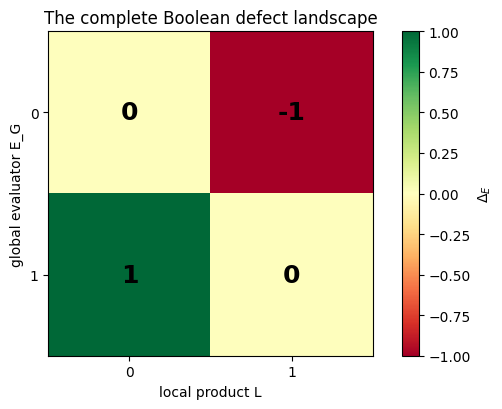

In [3]:
grid = np.array([[g - local for local in (0, 1)] for g in (0, 1)])
fig, ax = plt.subplots(figsize=(6.4, 4.2))
image = ax.imshow(grid, cmap="RdYlGn", vmin=-1, vmax=1)
for g in (0, 1):
    for local in (0, 1):
        ax.text(local, g, str(grid[g, local]), ha="center", va="center", fontsize=18, fontweight="bold")
ax.set(xticks=(0, 1), yticks=(0, 1), xlabel="local product L", ylabel="global evaluator E_G",
       title="The complete Boolean defect landscape")
fig.colorbar(image, ax=ax, label="$\\Delta_E$")
fig.tight_layout()
plt.show()

## 2. Practice: separate agreement from governance

The model records three governance checks:

- representation retains the required boundary information;
- the owner has both authority and accountability; and
- local and global verdicts refer to the same interval.

Checked-closure eligibility requires all three **and** zero defect. Change the controls below and watch those two questions remain separate.

In [4]:
def audit_boundary(e1=True, e2=True, eg=False, authority=True, accountability=False,
                   representation=True, timing=True):
    cut = BoundaryCut("demo", "input", "output")
    units = [FunctionUnit("left", "A"), FunctionUnit("right", "B")]
    validators = [
        LocalValidator("left check", units[0], lambda _: e1),
        LocalValidator("right check", units[1], lambda _: e2),
    ]
    owner = BoundaryOwner("owner", "interface lead", authority, accountability)
    system = OrganizationalEvaluatorSystem(cut, units, validators, lambda _: eg, owner)
    defect = system.evaluate({})
    governance = OrganizationalClosureConditions(representation, owner.is_complete, timing)
    result = governance.audit_boundary_governance(defect)
    display(Markdown(
        f"**Defect:** {defect.delta_E} ({defect.defect_sign.name})  \n"
        f"**Governance checks:** {governance.governance_prerequisites_satisfied}  \n"
        f"**Checked-closure eligible:** {result['closure_eligible']}"
    ))
    return defect, governance, result

controls = {
    "e1": widgets.ToggleButtons(options=(("0", False), ("1", True)), value=True, description="E1"),
    "e2": widgets.ToggleButtons(options=(("0", False), ("1", True)), value=True, description="E2"),
    "eg": widgets.ToggleButtons(options=(("0", False), ("1", True)), value=False, description="EG"),
    "authority": widgets.Checkbox(value=True, description="owner has authority"),
    "accountability": widgets.Checkbox(value=False, description="owner is accountable"),
    "representation": widgets.Checkbox(value=True, description="representation check"),
    "timing": widgets.Checkbox(value=True, description="timing check"),
}
output = widgets.interactive_output(audit_boundary, controls)
display(widgets.VBox([*controls.values(), output]))

In [5]:
defect, governance, result = audit_boundary(
    e1=True, e2=True, eg=False,
    authority=True, accountability=True,
    representation=True, timing=True,
)
assert defect.delta_E == -1
assert governance.governance_prerequisites_satisfied
assert not result["closure_eligible"]
print("Governance readiness does not force evaluator factorization.")

unit = FunctionUnit("detector", "demo")
copied_global = LocalValidator("copied global", unit, lambda trace: trace["g"])
failing_peer = LocalValidator("failing peer", unit, lambda trace: trace["peer"])
sample = [{"g": False, "peer": False}, {"g": True, "peer": False}]
assert not DetectorAdequacyGuard.is_aligned_validator_collapsing(
    [copied_global, failing_peer], sample, lambda trace: trace["g"]
)
display(Markdown("A copied global validator does **not** collapse the detector when a failing peer makes the complete product disagree with $E_G$."))

**Defect:** -1 (LOCAL_GREEN_GLOBAL_RED)  
**Governance checks:** True  
**Checked-closure eligible:** False

Governance readiness does not force evaluator factorization.


A copied global validator does **not** collapse the detector when a failing peer makes the complete product disagree with $E_G$.

## 3. Proof-level witnesses

Weak sufficiency means that the retained representation recovers $E_G$. It does not say that $E_G$ equals the local product. The next cell reproduces the same witness used in Lean.

The non-additivity result motivates keeping attribution separate; the next cell demonstrates one optional Shapley attribution.

In [6]:
counterexample = WeakSufficiencyAuditor.evaluate_counterexample()
assert counterexample == {
    "weak_sufficiency_holds": True,
    "g_auth": True,
    "g_time": True,
    "evaluator_factorization_holds": False,
    "delta_E": -1,
    "refutes_factorization_implication": True,
}

players = ["representation", "ownership", "timing"]
value = lambda coalition: float(set(players).issubset(coalition))
attribution = NonAdditivityAuditor.compute_shapley_attribution(players, value)
assert np.isclose(sum(attribution.values()), 1.0)
display(counterexample, attribution)

{'weak_sufficiency_holds': True,
 'g_auth': True,
 'g_time': True,
 'evaluator_factorization_holds': False,
 'delta_E': -1,
 'refutes_factorization_implication': True}

{'representation': 0.3333333333333333,
 'ownership': 0.3333333333333333,
 'timing': 0.3333333333333333}

## 4. Research view: why a quotient can fail

A carrier keeps only local information $J(x)$. Quotienting identifies traces with the same $J$ value. If two identified traces have different global verdicts, then no function on quotient classes can reproduce the global evaluator: a function must assign one value to one class.

Lean checks this argument in `boundary_carrier_mixing_blocks_quotient_factorization`. It also proves that if the shared class is locally green, one of the two different global verdicts produces $\Delta_E=-1$.

In [7]:
traces = [
    {"name": "x", "carrier": ("p", "q"), "global": 0},
    {"name": "x'", "carrier": ("p", "q"), "global": 1},
]
same_class = traces[0]["carrier"] == traces[1]["carrier"]
mixed_global = traces[0]["global"] != traces[1]["global"]
assert same_class and mixed_global
display(Markdown("One quotient class would need both global values **0** and **1**. Factorization is impossible."))

One quotient class would need both global values **0** and **1**. Factorization is impossible.

## 5. Break, observe, recover

Robust software should reject values outside the mathematical domain. Evaluator callbacks accept only exact Python `bool` values, not numeric stand-ins such as `0`, `1`, `0.0`, or `1.0`. Here a local evaluator emits 0.5; the implementation catches it. We then replace it with an explicit Boolean threshold and recover an integer-valued defect.

In [8]:
unit = FunctionUnit("demo", "lab")
bad = LocalValidator("bad", unit, lambda _: 0.5)
try:
    bad.evaluate({})
    raise AssertionError("the malformed verdict was accepted")
except ValueError as error:
    print(f"Caught the injected fault: {error}")

recovered = LocalValidator("recovered", unit, lambda _: 0.5 >= 1.0)
assert recovered.evaluate({}) == 0
print("Recovered with an explicit Boolean rule.")

Caught the injected fault: LocalValidator bad must return an exact bool, got float (0.5)
Recovered with an explicit Boolean rule.


## What to carry forward

- A negative defect is an exact witness of local pass and global failure.
- Zero defect records agreement, which can occur at failure or by detector collapse.
- Governance checks and evaluator agreement are different predicates.
- A global evaluator cannot descend to a quotient when it varies inside one quotient class.

The paper gives the full statements and maps each one to its Lean declaration and Python test.